# ✈️ Airline DW — Exploratory Data Analysis
CDIO Project

In [4]:
import sqlite3, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
conn = sqlite3.connect('../warehouse/airline_dw.db')
print('Connected!')

Connected!


## 1. Tổng quan dữ liệu

In [5]:
for t in ['dim_airline','dim_airport','dim_date','fact_flights']:
    n = pd.read_sql(f'SELECT COUNT(*) AS n FROM {t}', conn).iloc[0,0]
    print(f'{t:<25} {n:>10,} rows')

dim_airline                       14 rows
dim_airport                      322 rows
dim_date                         365 rows
fact_flights               5,332,914 rows


## 2. Phân bố delay

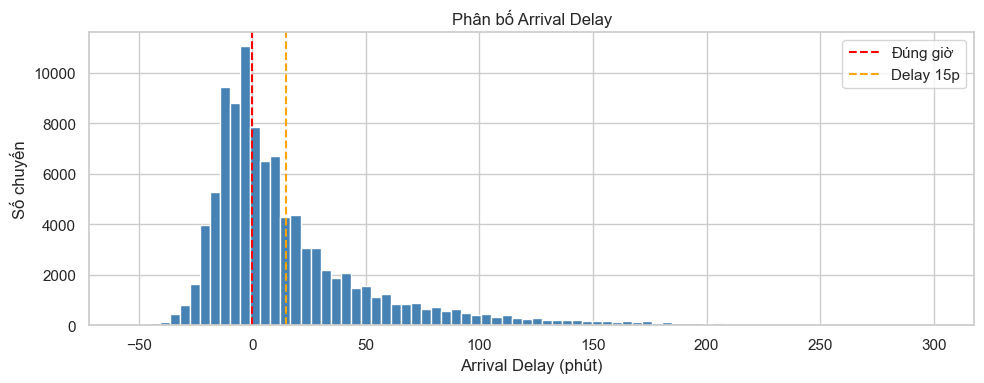

In [6]:
df = pd.read_sql('SELECT arrival_delay FROM fact_flights WHERE is_cancelled=0 AND arrival_delay BETWEEN -60 AND 300 LIMIT 100000', conn)
fig, ax = plt.subplots(figsize=(10,4))
ax.hist(df['arrival_delay'], bins=80, color='steelblue', edgecolor='white')
ax.axvline(0, color='red', linestyle='--', label='Đúng giờ')
ax.axvline(15, color='orange', linestyle='--', label='Delay 15p')
ax.set_xlabel('Arrival Delay (phút)'); ax.set_ylabel('Số chuyến')
ax.set_title('Phân bố Arrival Delay'); ax.legend()
plt.tight_layout(); plt.show()

## 3. OTP theo hãng

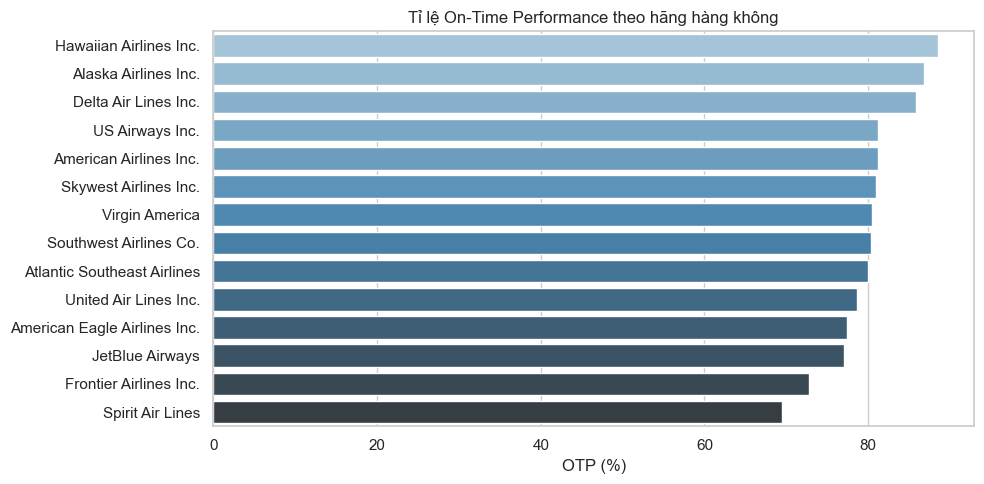

In [7]:
sql = '''
    SELECT a.airline_name,
           ROUND(100.0*(1-1.0*SUM(f.is_delayed_15)/COUNT(*)),1) AS otp_pct,
           COUNT(*) AS flights
    FROM fact_flights f JOIN dim_airline a ON f.airline_key=a.airline_key
    WHERE f.is_cancelled=0 GROUP BY a.airline_name HAVING flights>1000
    ORDER BY otp_pct DESC
'''
df_otp = pd.read_sql(sql, conn)
fig, ax = plt.subplots(figsize=(10,5))
sns.barplot(data=df_otp, y='airline_name', x='otp_pct', palette='Blues_d', ax=ax)
ax.set_xlabel('OTP (%)'); ax.set_ylabel('')
ax.set_title('Tỉ lệ On-Time Performance theo hãng hàng không')
plt.tight_layout(); plt.show()

## 4. Xu hướng delay theo tháng

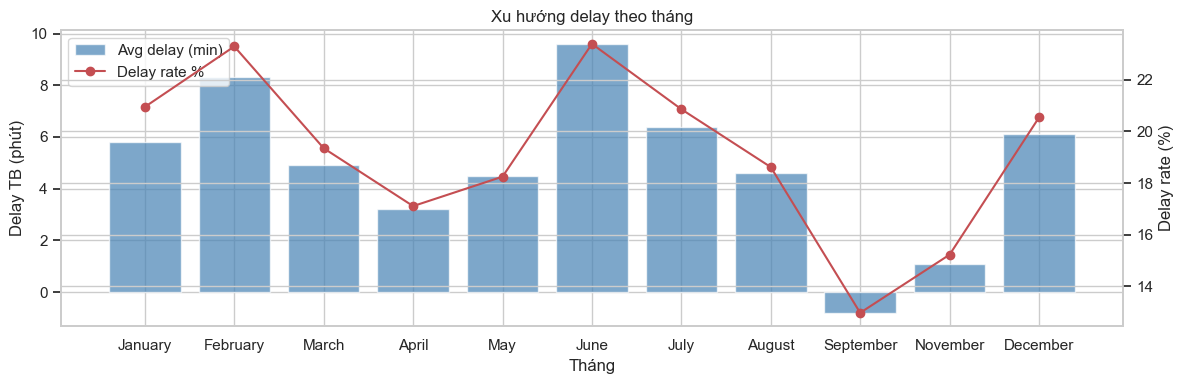

In [8]:
sql2 = '''
    SELECT d.month, d.month_name,
           ROUND(AVG(f.arrival_delay),1) AS avg_delay,
           ROUND(100.0*SUM(f.is_delayed_15)/COUNT(*),2) AS delay_rate
    FROM fact_flights f JOIN dim_date d ON f.date_key=d.date_key
    WHERE f.is_cancelled=0 GROUP BY d.month ORDER BY d.month
'''
df_m = pd.read_sql(sql2, conn)
fig, ax1 = plt.subplots(figsize=(12,4))
ax1.bar(df_m['month_name'], df_m['avg_delay'], color='steelblue', alpha=0.7, label='Avg delay (min)')
ax2 = ax1.twinx()
ax2.plot(df_m['month_name'], df_m['delay_rate'], 'r-o', label='Delay rate %')
ax1.set_xlabel('Tháng'); ax1.set_ylabel('Delay TB (phút)')
ax2.set_ylabel('Delay rate (%)')
ax1.set_title('Xu hướng delay theo tháng')
lines1, l1 = ax1.get_legend_handles_labels()
lines2, l2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, l1+l2, loc='upper left')
plt.tight_layout(); plt.show()

## 5. Correlation heatmap của các loại delay

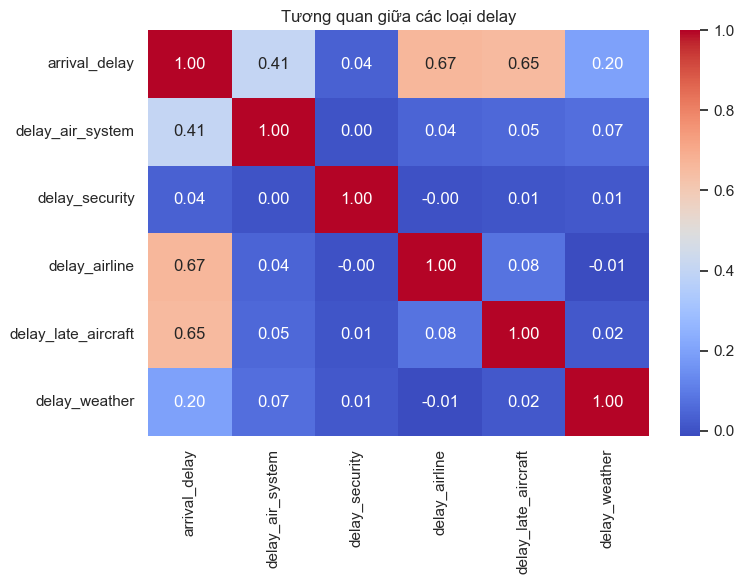

In [9]:
sql3 = '''
    SELECT arrival_delay, delay_air_system, delay_security,
           delay_airline, delay_late_aircraft, delay_weather
    FROM fact_flights WHERE is_cancelled=0 LIMIT 50000
'''
df_corr = pd.read_sql(sql3, conn)
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Tương quan giữa các loại delay')
plt.tight_layout(); plt.show()

In [10]:
conn.close()
print('Done!')

Done!
